In [22]:
from statistics import LinearRegression

import scipy
import numpy as np
import matplotlib as mpl
import pandas as pd
import sklearn as skl
import seaborn as sns

import matplotlib.pyplot as plt

In [16]:
import sys

In [17]:
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/iris/iris.data"
names = ['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'class']
df = pd.read_csv(url, names=names)

In [18]:
print(df.shape)
print(df.head(20))

(150, 5)
    sepal_length  sepal_width  petal_length  petal_width        class
0            5.1          3.5           1.4          0.2  Iris-setosa
1            4.9          3.0           1.4          0.2  Iris-setosa
2            4.7          3.2           1.3          0.2  Iris-setosa
3            4.6          3.1           1.5          0.2  Iris-setosa
4            5.0          3.6           1.4          0.2  Iris-setosa
5            5.4          3.9           1.7          0.4  Iris-setosa
6            4.6          3.4           1.4          0.3  Iris-setosa
7            5.0          3.4           1.5          0.2  Iris-setosa
8            4.4          2.9           1.4          0.2  Iris-setosa
9            4.9          3.1           1.5          0.1  Iris-setosa
10           5.4          3.7           1.5          0.2  Iris-setosa
11           4.8          3.4           1.6          0.2  Iris-setosa
12           4.8          3.0           1.4          0.1  Iris-setosa
13         

In [19]:
print(df.groupby('class').size())

class
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
dtype: int64


In [20]:
df.describe()

,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.054000,3.758667,1.198667
std,0.828066,0.433594,1.764420,0.763161
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [21]:
col = "sepal_length"
df[col]

0      5.1
1      4.9
2      4.7
3      4.6
4      5.0
      ... 
145    6.7
146    6.3
147    6.5
148    6.2
149    5.9
Name: sepal_length, Length: 150, dtype: float64

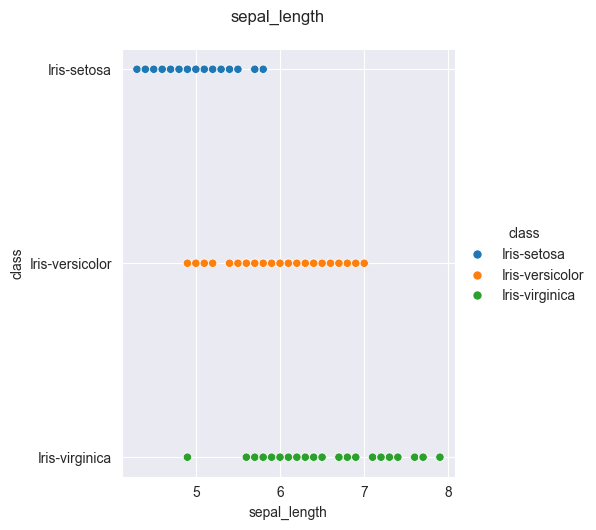

In [23]:
sns.relplot(x=col, y="class", hue="class", data=df)
_ = plt.suptitle(col, y=1.05)

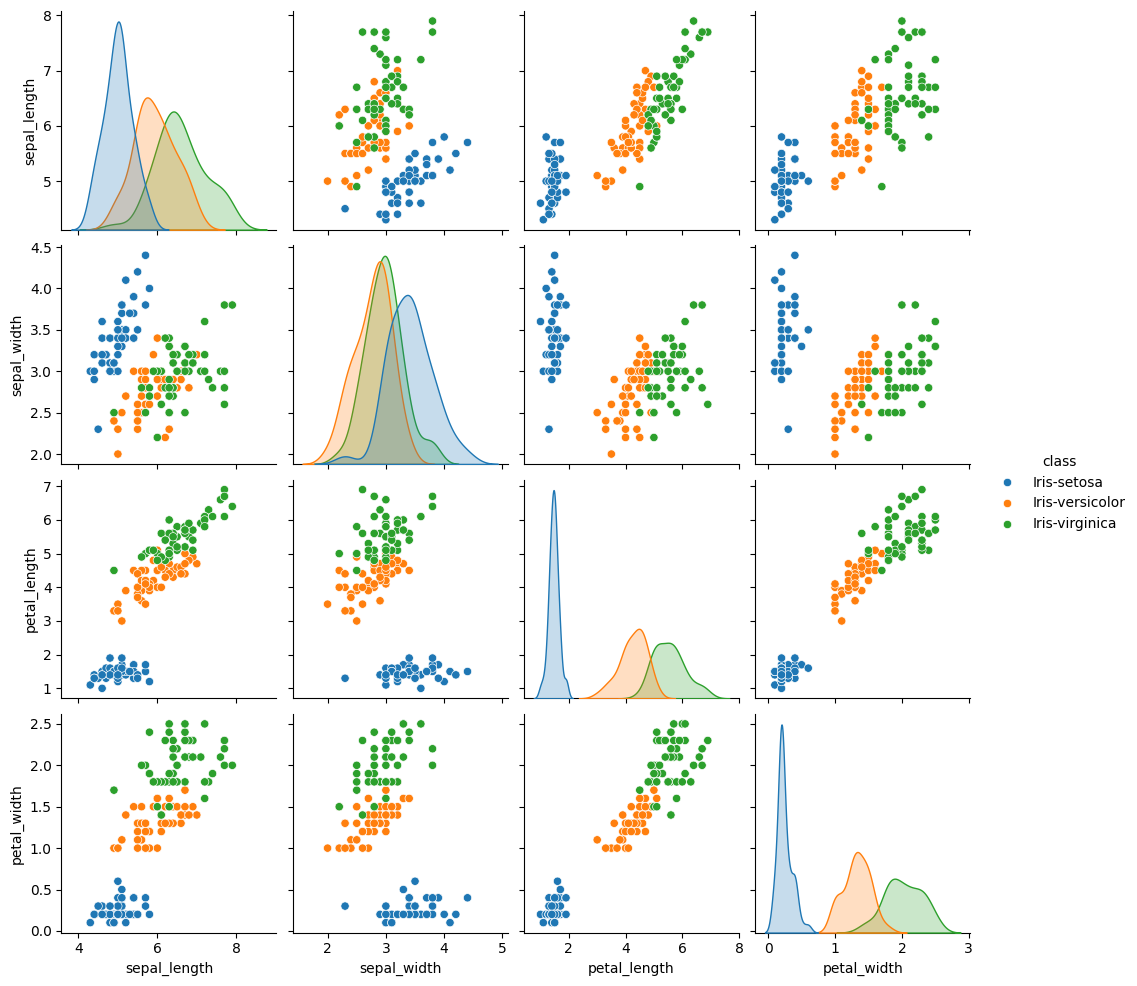

In [19]:
sns.pairplot(df, hue="class")

Train Test Split

In [52]:
from sklearn.model_selection import train_test_split

df_train, df_test = train_test_split(df, test_size=0.25, random_state=40)
df_train, df_val = train_test_split(df_train, test_size=0.25, random_state=40)

In [53]:
X_train = df_train.drop(columns=["class"]).values
y_train = df_train["class"].values
X_test = df_test.drop(columns=["class"]).values
y_test = df_test["class"].values
X_val = df_val.drop(columns=["class"]).values
y_val = df_val["class"].values

In [54]:
X_train.shape

(84, 4)

Choosing a Model

What is our baseline (Random guessing or assuming all flowers are the same) ?

Since we have 3 flowers/classes, it is 33% acurracy

Making and fitting the model

In [64]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=100)
model.fit(X_train, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [ ]:
Validating

In [66]:
model.score(X_val, y_val)

0.9285714285714286

In [63]:
model.score(X_train, y_train)

0.9761904761904762

Cross Validation

In [67]:
from sklearn.model_selection import cross_val_score, cross_val_predict

In [68]:
model_2 = LogisticRegression()

cross_val_score(model_2, X_train, y_train, cv=5, scoring="accuracy")

array([0.94117647, 0.88235294, 1.        , 1.        , 0.875     ])

Where are we misclassifying points?

In [69]:
y_pred = cross_val_predict(model_2, X_train, y_train, cv=5)

In [78]:
correct_predictions_mask = y_pred == y_train
incorrect_predictions_mask = ~correct_predictions_mask

In [77]:
X_train[incorrect_predictions_mask]

array([[6. , 3. , 4.8, 1.8],
       [6.3, 2.8, 5.1, 1.5],
       [6. , 2.2, 5. , 1.5],
       [6.3, 2.5, 4.9, 1.5],
       [6. , 2.7, 5.1, 1.6]])

Now that we know which ones we got wrong, let's add this as a bool column to predictions

In [80]:
df_train_predictions = df_train.copy() # start with fresh training data
df_train_predictions["Predicted_class"] = y_pred # add in best guess prediction
df_train_predictions["Accurate"] = correct_predictions_mask


In [82]:
df_train_predictions[incorrect_predictions_mask]

,sepal_length,sepal_width,petal_length,petal_width,class,Predicted_class,Accurate
138,6.0,3.0,4.8,1.8,Iris-virginica,Iris-versicolor,False
133,6.3,2.8,5.1,1.5,Iris-virginica,Iris-versicolor,False
119,6.0,2.2,5.0,1.5,Iris-virginica,Iris-versicolor,False
72,6.3,2.5,4.9,1.5,Iris-versicolor,Iris-virginica,False
83,6.0,2.7,5.1,1.6,Iris-versicolor,Iris-virginica,False


In [85]:
sns.scatterplot(x="petal_length", y="petal_width", hue="Accurate", data=df_train_predictions)

ValueError: Length of list vectors must match length of `data` when both are used, but `data` has length 84 and the vector passed to `hue` has length 2.